<a href="https://colab.research.google.com/github/alfionsoderoso7/credit-default-prediction/blob/main/Credit_Default_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UTS Prediksi Modern & Machine Learning
## Experiment Challenge: Credit Default Prediction

Dataset: *Default of Credit Card Clients* (UCI / Kaggle) | Target: `default.payment.next.month` | Metrik utama: **F1-score (kelas 1 = default)**

**Cara menjalankan:** `Runtime > Run all`. Saat diminta, upload file `UCI_Credit_Card.csv`. Semua angka di PDF Final Analysis dihasilkan otomatis dari notebook ini (cell paling akhir), sehingga konsisten dengan output notebook.

In [4]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42
sns.set_style("whitegrid")

In [5]:
# Load dataset (raw, tanpa modifikasi)
PATH = "UCI_Credit_Card.csv"
if not os.path.exists(PATH):
    from google.colab import files
    uploaded = files.upload()          # pilih UCI_Credit_Card.csv
    PATH = list(uploaded.keys())[0]
df = pd.read_csv(PATH)
print("Berhasil membaca:", PATH)

Berhasil membaca: UCI_Credit_Card.csv


---
# Experiment 0 — Data Understanding & Preparation

In [6]:
TARGET = "default.payment.next.month"
print("Dimensi dataset (baris, kolom):", df.shape)
display(df.head())
print("\nStruktur dan tipe data:")
df.info()
print("\nVariabel target:", TARGET, "| nilai unik:", sorted(df[TARGET].unique()))

Dimensi dataset (baris, kolom): (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0



Struktur dan tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_A

In [7]:
# Missing value dan duplicate
print("Total missing value:", int(df.isna().sum().sum()))
print("ID duplikat        :", int(df["ID"].duplicated().sum()))

fitur_cols = [c for c in df.columns if c not in ["ID", TARGET]]
n_dup = int(df.duplicated(subset=fitur_cols + [TARGET]).sum())
print("Baris duplikat (semua fitur + target sama, ID diabaikan):", n_dup)

Total missing value: 0
ID duplikat        : 0
Baris duplikat (semua fitur + target sama, ID diabaikan): 35


In [8]:
# Pemeriksaan nilai tidak sesuai / tidak wajar
cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
payamt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

for c in cat_cols:
    print(f"\n{c}:\n", df[c].value_counts().sort_index().to_dict())

print("\nPAY_x (gabungan 6 kolom):")
print(pd.Series(df[pay_cols].values.ravel()).value_counts().sort_index().to_dict())

print("\nEDUCATION di luar {1,2,3,4}:", int((~df["EDUCATION"].isin([1,2,3,4])).sum()), "baris")
print("MARRIAGE di luar {1,2,3}   :", int((~df["MARRIAGE"].isin([1,2,3])).sum()), "baris")
print("LIMIT_BAL <= 0             :", int((df["LIMIT_BAL"] <= 0).sum()))
print("AGE min/max                :", df["AGE"].min(), "/", df["AGE"].max())
print("BILL_AMT negatif per kolom :", {c: int((df[c] < 0).sum()) for c in bill_cols})
print("PAY_AMT negatif per kolom  :", {c: int((df[c] < 0).sum()) for c in payamt_cols})
display(df[["LIMIT_BAL", "AGE"] + bill_cols + payamt_cols].describe().T)


SEX:
 {1: 11888, 2: 18112}

EDUCATION:
 {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}

MARRIAGE:
 {0: 54, 1: 13659, 2: 15964, 3: 323}

PAY_x (gabungan 6 kolom):
{-2: 24415, -1: 34640, 0: 95919, 1: 3722, 2: 18964, 3: 1430, 4: 453, 5: 137, 6: 74, 7: 218, 8: 28}

EDUCATION di luar {1,2,3,4}: 345 baris
MARRIAGE di luar {1,2,3}   : 54 baris
LIMIT_BAL <= 0             : 0
AGE min/max                : 21 / 79
BILL_AMT negatif per kolom : {'BILL_AMT1': 590, 'BILL_AMT2': 669, 'BILL_AMT3': 655, 'BILL_AMT4': 675, 'BILL_AMT5': 655, 'BILL_AMT6': 688}
PAY_AMT negatif per kolom  : {'PAY_AMT1': 0, 'PAY_AMT2': 0, 'PAY_AMT3': 0, 'PAY_AMT4': 0, 'PAY_AMT5': 0, 'PAY_AMT6': 0}


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
BILL_AMT1,30000.0,51223.330900,73635.860576,-165580.0,3558.75,22381.5,67091.00,964511.0
BILL_AMT2,30000.0,49179.075167,71173.768783,-69777.0,2984.75,21200.0,64006.25,983931.0
BILL_AMT3,30000.0,47013.154800,69349.387427,-157264.0,2666.25,20088.5,60164.75,1664089.0
BILL_AMT4,30000.0,43262.948967,64332.856134,-170000.0,2326.75,19052.0,54506.00,891586.0
BILL_AMT5,30000.0,40311.400967,60797.155770,-81334.0,1763.00,18104.5,50190.50,927171.0
BILL_AMT6,30000.0,38871.760400,59554.107537,-339603.0,1256.00,17071.0,49198.25,961664.0
PAY_AMT1,30000.0,5663.580500,16563.280354,0.0,1000.00,2100.0,5006.00,873552.0
PAY_AMT2,30000.0,5921.163500,23040.870402,0.0,833.00,2009.0,5000.00,1684259.0


{0: 23364, 1: 6636} | proporsi: {0: 0.7788, 1: 0.2212}


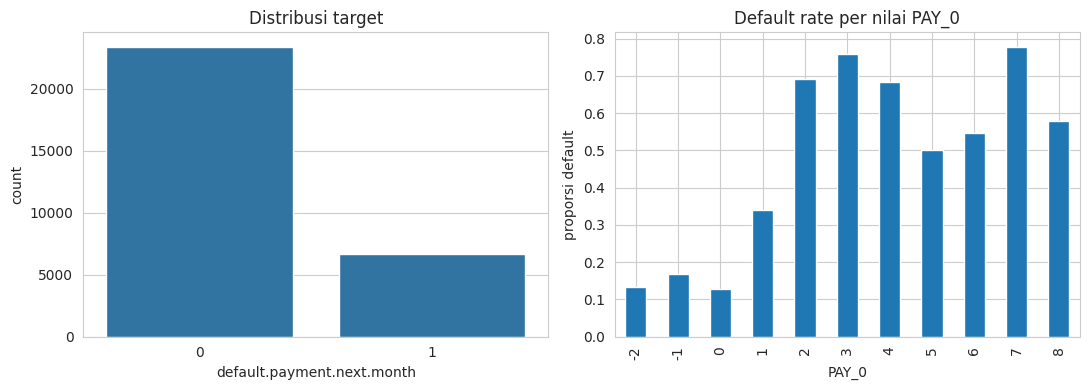

In [9]:
# Distribusi target
cnt = df[TARGET].value_counts().sort_index()
print(cnt.to_dict(), "| proporsi:", (cnt / cnt.sum()).round(4).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x=TARGET, data=df, ax=ax[0]); ax[0].set_title("Distribusi target")
df.groupby("PAY_0")[TARGET].mean().plot(kind="bar", ax=ax[1])
ax[1].set_title("Default rate per nilai PAY_0"); ax[1].set_ylabel("proporsi default")
plt.tight_layout(); plt.show()

### Ringkasan temuan & keputusan Experiment 0
- **Missing value: 0** pada seluruh kolom, sehingga tidak diperlukan imputasi.
- **Duplikat:** ada baris yang identik pada seluruh fitur+target (ID diabaikan). Baris duplikat dibuang **sebelum split** supaya baris identik tidak muncul di train dan test sekaligus (potensi leakage). Jumlahnya sangat kecil dibanding 30.000 baris.
- **Nilai tidak sesuai:** `EDUCATION` memiliki kode 0, 5, 6 yang tidak ada di dokumentasi (1-4); `MARRIAGE` memiliki kode 0 (dokumentasi 1-3). Keduanya akan digabung ke kategori "lainnya" (4 dan 3) pada Experiment 2. `PAY_x` memiliki nilai -2 dan 0 yang tidak dijelaskan di deskripsi dataset, tetapi nilainya konsisten secara ordinal sehingga dibiarkan apa adanya.
- **Nilai negatif pada `BILL_AMT`** dapat terjadi secara wajar (kelebihan bayar), maka tidak dibuang.
- **Target tidak seimbang** (sekitar 22% default), sehingga *accuracy* menyesatkan dan F1 kelas default dipakai sebagai metrik utama.
- `ID` dikeluarkan dari predictor. Train-test split dilakukan **sebelum** training, stratified, 80:20. Scaling/encoding dimasukkan ke dalam `Pipeline` agar hanya di-*fit* pada data training di setiap fold (tanpa data leakage).

In [10]:
# Buang duplikat, tentukan predictor & target, lalu train-test split (stratified)
df_model = df.drop_duplicates(subset=fitur_cols + [TARGET]).reset_index(drop=True)
print(f"Baris sebelum: {len(df)} | sesudah buang duplikat: {len(df_model)}")

X = df_model.drop(columns=["ID", TARGET])
y = df_model[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Proporsi default train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))
print("Predictor:", list(X.columns))

Baris sebelum: 30000 | sesudah buang duplikat: 29965
X_train: (23972, 23) | X_test: (5993, 23)
Proporsi default train: 0.2213 | test: 0.2213
Predictor: ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


In [11]:
# Prosedur evaluasi yang sama untuk semua model
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"f1": "f1", "accuracy": "accuracy", "precision": "precision", "recall": "recall"}
results, fitted = [], {}

def evaluate(exp, name, base, model, show=True):
    """5-fold CV (F1) pada training set + evaluasi pada test set."""
    t0 = time.time()
    cvr = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    row = dict(Experiment=exp, Model=name, Base=base,
               CV_F1=cvr["test_f1"].mean(), CV_F1_std=cvr["test_f1"].std(),
               Test_Accuracy=accuracy_score(y_test, pred),
               Test_Precision=precision_score(y_test, pred, zero_division=0),
               Test_Recall=recall_score(y_test, pred, zero_division=0),
               Test_F1=f1_score(y_test, pred, zero_division=0))
    results.append(row); fitted[(exp, name)] = model
    if show:
        print(f"[Exp {exp}] {name}  ({time.time()-t0:.0f}s)")
        print(f"  CV F1 = {row['CV_F1']:.4f} (+/- {row['CV_F1_std']:.4f})")
        print(f"  Test  : Acc={row['Test_Accuracy']:.4f}  Prec={row['Test_Precision']:.4f}  "
              f"Rec={row['Test_Recall']:.4f}  F1={row['Test_F1']:.4f}")
    return row

def vonis(delta, tol=0.005):
    if delta >= tol: return "meningkat"
    if delta <= -tol: return "menurun"
    return "tidak berubah berarti"

---
# Experiment 1 — Baseline Model (Logistic Regression, data mentah)
Tanpa cleaning kategori, tanpa encoding, tanpa scaling.

In [12]:
base1 = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
r1 = evaluate("1", "Logistic Regression - Baseline (raw)", "Logistic Regression", base1)
y_pred_b = fitted[("1", r1["Model"])].predict(X_test)
print("\nJumlah prediksi default di test:", int(y_pred_b.sum()), "dari", len(y_pred_b),
      "| aktual default:", int(y_test.sum()))

[Exp 1] Logistic Regression - Baseline (raw)  (38s)
  CV F1 = 0.3576 (+/- 0.0131)
  Test  : Acc=0.8093  Prec=0.6976  Rec=0.2436  F1=0.3611

Jumlah prediksi default di test: 463 dari 5993 | aktual default: 1326


---
# Experiment 2 — Preprocessing
Dua varian dibandingkan, lalu **satu dipilih berdasarkan CV F1 (bukan test)**:
- **2a:** cleaning kategori (EDUCATION 0/5/6 → 4, MARRIAGE 0 → 3) + One-Hot Encoding (`SEX`, `EDUCATION`, `MARRIAGE`) + StandardScaler untuk fitur numerik.
- **2b:** 2a + `class_weight="balanced"` untuk menangani ketidakseimbangan kelas (dilakukan di dalam model, bukan resampling, sehingga tidak ada leakage ke fold validasi).

In [13]:
cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]
num_cols = [c for c in X.columns if c not in cat_cols]

def clean_categories(d):
    d = d.copy()
    d["EDUCATION"] = d["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
    d["MARRIAGE"] = d["MARRIAGE"].replace({0: 3})
    return d

def make_preprocessor():
    ct = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler(), num_cols)])
    return Pipeline([("clean", FunctionTransformer(clean_categories)), ("ct", ct)])

def make_pipe(clf):
    return Pipeline([("prep", make_preprocessor()), ("model", clf)])

r2a = evaluate("2a", "Logistic Regression - Preprocessing (clean+OHE+scale)", "Logistic Regression",
               make_pipe(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)))
r2b = evaluate("2b", "Logistic Regression - Preprocessing + class_weight", "Logistic Regression",
               make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)))

exp2 = max([r2a, r2b], key=lambda r: r["CV_F1"])
CW = "balanced" if exp2["Experiment"] == "2b" else None
print(f"\nVarian terpilih (CV F1 tertinggi): {exp2['Experiment']}  -> class_weight = {CW}")

comp = pd.DataFrame([r1, r2a, r2b]).set_index("Experiment")[
    ["CV_F1", "Test_Accuracy", "Test_Precision", "Test_Recall", "Test_F1"]]
display(comp.round(4))
print(f"Perubahan CV F1 (terpilih vs baseline)  : {exp2['CV_F1']-r1['CV_F1']:+.4f}  -> {vonis(exp2['CV_F1']-r1['CV_F1'])}")
print(f"Perubahan Test F1 (terpilih vs baseline): {exp2['Test_F1']-r1['Test_F1']:+.4f}  -> {vonis(exp2['Test_F1']-r1['Test_F1'])}")
print(f"Perubahan CV F1 preprocessing murni (2a vs 1): {r2a['CV_F1']-r1['CV_F1']:+.4f}")

[Exp 2a] Logistic Regression - Preprocessing (clean+OHE+scale)  (1s)
  CV F1 = 0.3576 (+/- 0.0112)
  Test  : Acc=0.8136  Prec=0.7267  Rec=0.2526  F1=0.3749
[Exp 2b] Logistic Regression - Preprocessing + class_weight  (1s)
  CV F1 = 0.4778 (+/- 0.0108)
  Test  : Acc=0.6828  Prec=0.3723  Rec=0.6320  F1=0.4685

Varian terpilih (CV F1 tertinggi): 2b  -> class_weight = balanced


,CV_F1,Test_Accuracy,Test_Precision,Test_Recall,Test_F1
Experiment,,,,,
1,0.3576,0.8093,0.6976,0.2436,0.3611
2a,0.3576,0.8136,0.7267,0.2526,0.3749
2b,0.4778,0.6828,0.3723,0.6320,0.4685


Perubahan CV F1 (terpilih vs baseline)  : +0.1202  -> meningkat
Perubahan Test F1 (terpilih vs baseline): +0.1075  -> meningkat
Perubahan CV F1 preprocessing murni (2a vs 1): -0.0000


---
# Experiment 3 — Model Comparison
Logistic Regression, Decision Tree, Random Forest dengan preprocessing dan `class_weight` hasil Experiment 2, hyperparameter default (kecuali `random_state`). Model terbaik dipilih berdasarkan **CV F1**.

In [14]:
factories = {
    "Logistic Regression": lambda: LogisticRegression(max_iter=2000, class_weight=CW, random_state=RANDOM_STATE),
    "Decision Tree":       lambda: DecisionTreeClassifier(class_weight=CW, random_state=RANDOM_STATE),
    "Random Forest":       lambda: RandomForestClassifier(n_estimators=100, class_weight=CW, random_state=RANDOM_STATE),
}
exp3_rows = [evaluate("3", name, name, make_pipe(f())) for name, f in factories.items()]

exp3_best = max(exp3_rows, key=lambda r: r["CV_F1"])
tbl3 = pd.DataFrame(exp3_rows).set_index("Model")[
    ["CV_F1", "CV_F1_std", "Test_Accuracy", "Test_Precision", "Test_Recall", "Test_F1"]]
display(tbl3.round(4))
print("Model terbaik (CV F1):", exp3_best["Model"])
print("Model terbaik (Test F1):", max(exp3_rows, key=lambda r: r["Test_F1"])["Model"])

[Exp 3] Logistic Regression  (1s)
  CV F1 = 0.4778 (+/- 0.0108)
  Test  : Acc=0.6828  Prec=0.3723  Rec=0.6320  F1=0.4685
[Exp 3] Decision Tree  (4s)
  CV F1 = 0.3894 (+/- 0.0157)
  Test  : Acc=0.7248  Prec=0.3790  Rec=0.3816  F1=0.3803
[Exp 3] Random Forest  (46s)
  CV F1 = 0.4502 (+/- 0.0143)
  Test  : Acc=0.8101  Prec=0.6354  Rec=0.3326  F1=0.4366


,CV_F1,CV_F1_std,Test_Accuracy,Test_Precision,Test_Recall,Test_F1
Model,,,,,,
Logistic Regression,0.4778,0.0108,0.6828,0.3723,0.6320,0.4685
Decision Tree,0.3894,0.0157,0.7248,0.3790,0.3816,0.3803
Random Forest,0.4502,0.0143,0.8101,0.6354,0.3326,0.4366


Model terbaik (CV F1): Logistic Regression
Model terbaik (Test F1): Logistic Regression


---
# Experiment 4 — Hyperparameter Tuning (GridSearchCV, 5-fold, scoring = F1)
Tuning dilakukan pada model terbaik dari Experiment 3. **Catatan waktu:** untuk Random Forest bisa memakan beberapa menit di Colab.

In [15]:
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10, 100],
                            "model__solver": ["lbfgs", "liblinear"]},
    "Decision Tree": {"model__max_depth": [3, 5, 7, 10, None],
                      "model__min_samples_leaf": [1, 10, 50, 100],
                      "model__criterion": ["gini", "entropy"]},
    "Random Forest": {"model__n_estimators": [200, 300],
                      "model__max_depth": [6, 10, 15],
                      "model__min_samples_leaf": [5, 20],
                      "model__max_features": ["sqrt", 0.5]},
}
best_base = exp3_best["Base"]
grid = param_grids[best_base]
print("Model yang di-tuning:", best_base)
print("Hyperparameter yang diuji:")
for k, v in grid.items(): print("  ", k.replace("model__", ""), "=", v)

t0 = time.time()
gs = GridSearchCV(make_pipe(factories[best_base]()), grid, scoring="f1", cv=cv, n_jobs=-1, refit=True)
gs.fit(X_train, y_train)
print(f"\nGridSearchCV selesai ({time.time()-t0:.0f}s)")
print("Kombinasi terbaik :", {k.replace("model__", ""): v for k, v in gs.best_params_.items()})
print(f"Best CV F1 (GridSearch): {gs.best_score_:.4f}")

cvdf = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")
display(cvdf[["rank_test_score", "mean_test_score", "std_test_score", "params"]].head(5))

Model yang di-tuning: Logistic Regression
Hyperparameter yang diuji:
   C = [0.01, 0.1, 1, 10, 100]
   solver = ['lbfgs', 'liblinear']

GridSearchCV selesai (6s)
Kombinasi terbaik : {'C': 0.01, 'solver': 'lbfgs'}
Best CV F1 (GridSearch): 0.4797


,rank_test_score,mean_test_score,std_test_score,params
0,1,0.479663,0.008749,"{'model__C': 0.01, 'model__solver': 'lbfgs'}"
1,2,0.479437,0.008917,"{'model__C': 0.01, 'model__solver': 'liblinear'}"
3,3,0.478983,0.010829,"{'model__C': 0.1, 'model__solver': 'liblinear'}"
2,4,0.478857,0.011225,"{'model__C': 0.1, 'model__solver': 'lbfgs'}"
5,5,0.478123,0.010568,"{'model__C': 1, 'model__solver': 'liblinear'}"


In [16]:
tuned_name = f"{best_base} (tuned)"
exp4 = evaluate("4", tuned_name, best_base, clone(gs.best_estimator_))

cmp4 = pd.DataFrame([exp3_best, exp4]).assign(Tahap=["Sebelum tuning", "Setelah tuning"]).set_index("Tahap")[
    ["CV_F1", "Test_Accuracy", "Test_Precision", "Test_Recall", "Test_F1"]]
display(cmp4.round(4))
print(f"Delta CV F1  : {exp4['CV_F1']-exp3_best['CV_F1']:+.4f} -> {vonis(exp4['CV_F1']-exp3_best['CV_F1'])}")
print(f"Delta Test F1: {exp4['Test_F1']-exp3_best['Test_F1']:+.4f} -> {vonis(exp4['Test_F1']-exp3_best['Test_F1'])}")
print("Catatan: best CV F1 dari GridSearch cenderung sedikit optimis karena dipilih sebagai nilai maksimum dari banyak kombinasi.")

[Exp 4] Logistic Regression (tuned)  (1s)
  CV F1 = 0.4797 (+/- 0.0087)
  Test  : Acc=0.6878  Prec=0.3774  Rec=0.6327  F1=0.4728


,CV_F1,Test_Accuracy,Test_Precision,Test_Recall,Test_F1
Tahap,,,,,
Sebelum tuning,0.4778,0.6828,0.3723,0.6320,0.4685
Setelah tuning,0.4797,0.6878,0.3774,0.6327,0.4728


Delta CV F1  : +0.0018 -> tidak berubah berarti
Delta Test F1: +0.0043 -> tidak berubah berarti
Catatan: best CV F1 dari GridSearch cenderung sedikit optimis karena dipilih sebagai nilai maksimum dari banyak kombinasi.


---
# Experiment 5 — Advanced Model
- **XGBoost** (`scale_pos_weight` mengikuti pilihan class_weight dari Experiment 2)
- **HistGradientBoosting** (gradient boosting scikit-learn, `class_weight` mengikuti Experiment 2)

Hyperparameter kedua model ditetapkan di awal (konservatif, tanpa tuning). Ini disengaja agar tidak ada percobaan tambahan di luar ketentuan, tetapi artinya perbandingan dengan Random Forest yang sudah di-tuning **tidak sepenuhnya setara** (lihat catatan di analisis akhir).

In [17]:
spw = (y_train == 0).sum() / (y_train == 1).sum() if CW == "balanced" else 1.0
xgb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                    colsample_bytree=0.8, scale_pos_weight=spw, eval_metric="logloss",
                    random_state=RANDOM_STATE, n_jobs=1)
hgb = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_leaf_nodes=15,
                                     class_weight=CW, random_state=RANDOM_STATE)
r5a = evaluate("5a", "XGBoost", "XGBoost", make_pipe(xgb))
r5b = evaluate("5b", "HistGradientBoosting", "HistGradientBoosting", make_pipe(hgb))

exp5 = max([r5a, r5b], key=lambda r: r["CV_F1"])
print("\nModel advanced terpilih (CV F1):", exp5["Model"])
cmp5 = pd.DataFrame([exp4, exp5]).set_index("Model")[
    ["CV_F1", "Test_Accuracy", "Test_Precision", "Test_Recall", "Test_F1"]]
display(cmp5.round(4))
print(f"Delta CV F1  : {exp5['CV_F1']-exp4['CV_F1']:+.4f} -> {vonis(exp5['CV_F1']-exp4['CV_F1'])}")
print(f"Delta Test F1: {exp5['Test_F1']-exp4['Test_F1']:+.4f} -> {vonis(exp5['Test_F1']-exp4['Test_F1'])}")

[Exp 5a] XGBoost  (7s)
  CV F1 = 0.5384 (+/- 0.0090)
  Test  : Acc=0.7565  Prec=0.4629  Rec=0.6259  F1=0.5322
[Exp 5b] HistGradientBoosting  (4s)
  CV F1 = 0.5411 (+/- 0.0098)
  Test  : Acc=0.7514  Prec=0.4557  Rec=0.6357  F1=0.5309

Model advanced terpilih (CV F1): HistGradientBoosting


,CV_F1,Test_Accuracy,Test_Precision,Test_Recall,Test_F1
Model,,,,,
Logistic Regression (tuned),0.4797,0.6878,0.3774,0.6327,0.4728
HistGradientBoosting,0.5411,0.7514,0.4557,0.6357,0.5309


Delta CV F1  : +0.0614 -> meningkat
Delta Test F1: +0.0580 -> meningkat


---
# Final Analysis — Ringkasan, Pemilihan Model Final, dan PDF
**Aturan pemilihan model final (ditetapkan sebelum melihat hasil akhir):** kandidat = model terpilih dari Exp 2, 3, 4, dan 5. Dipilih berdasarkan **CV F1 tertinggi**; jika selisih CV F1 ≤ 0,003 dari yang tertinggi (praktis setara), dipilih model **yang lebih sederhana**. Test set dipakai sebagai konfirmasi akhir, tidak untuk memilih.

,Experiment,Model,CV_F1,Test_Accuracy,Test_Precision,Test_Recall,Test_F1
0,1,Logistic Regression - Baseline (raw),0.3576,0.8093,0.6976,0.2436,0.3611
1,2a,Logistic Regression - Preprocessing (clean+OHE...,0.3576,0.8136,0.7267,0.2526,0.3749
2,2b,Logistic Regression - Preprocessing + class_we...,0.4778,0.6828,0.3723,0.6320,0.4685
3,3,Logistic Regression,0.4778,0.6828,0.3723,0.6320,0.4685
4,3,Decision Tree,0.3894,0.7248,0.3790,0.3816,0.3803
5,3,Random Forest,0.4502,0.8101,0.6354,0.3326,0.4366
6,4,Logistic Regression (tuned),0.4797,0.6878,0.3774,0.6327,0.4728
7,5a,XGBoost,0.5384,0.7565,0.4629,0.6259,0.5322
8,5b,HistGradientBoosting,0.5411,0.7514,0.4557,0.6357,0.5309


Kandidat dalam toleransi: [('5b', 'HistGradientBoosting', 0.5411)]
MODEL FINAL: 5b - HistGradientBoosting


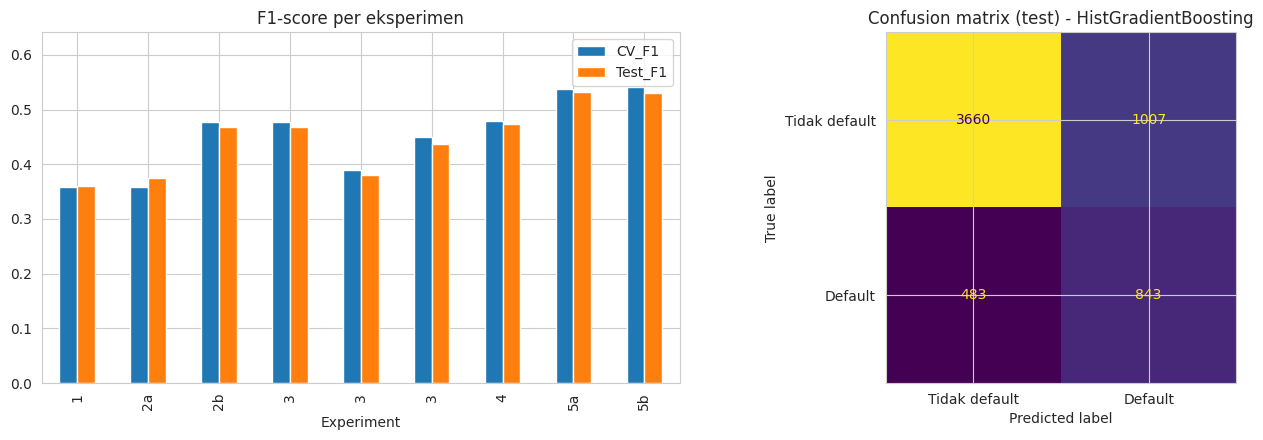

In [18]:
res = pd.DataFrame(results)
cols = ["Experiment", "Model", "CV_F1", "Test_Accuracy", "Test_Precision", "Test_Recall", "Test_F1"]
summary = res[cols].copy()
display(summary.round(4))
res.to_csv("hasil_eksperimen.csv", index=False)

# Pemilihan model final
complexity = {"Logistic Regression": 1, "Decision Tree": 2, "Random Forest": 3,
              "HistGradientBoosting": 4, "XGBoost": 4}
candidates = [exp2, exp3_best, exp4, exp5]
TOL = 0.003
top = max(c["CV_F1"] for c in candidates)
pool = [c for c in candidates if c["CV_F1"] >= top - TOL]
final = min(pool, key=lambda c: (complexity[c["Base"]], -c["CV_F1"]))
print("Kandidat dalam toleransi:", [(c["Experiment"], c["Model"], round(float(c["CV_F1"]), 4)) for c in pool])
print("MODEL FINAL:", final["Experiment"], "-", final["Model"])

# Visualisasi
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
plot_df = res.set_index("Experiment")[["CV_F1", "Test_F1"]]
plot_df.plot(kind="bar", ax=ax[0]); ax[0].set_title("F1-score per eksperimen"); ax[0].set_ylim(0, plot_df.values.max() + 0.1)
final_model = fitted[(final["Experiment"], final["Model"])]
ConfusionMatrixDisplay(confusion_matrix(y_test, final_model.predict(X_test)),
                       display_labels=["Tidak default", "Default"]).plot(ax=ax[1], colorbar=False)
ax[1].set_title(f"Confusion matrix (test) - {final['Model']}")
plt.tight_layout(); plt.savefig("grafik_final.png", dpi=150); plt.show()